# 简单神经网络

本实验使用 TensorFlow 搭建一个小型神经网络，给出两个特征：温度和时长，预测咖啡烘焙时间。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense
from lab_utils_common import dlc
from lab_coffee_utils import load_coffee_data, plt_roast, plt_prob, plt_layer, plt_network, plt_output_unit
import logging
logging.getLogger("tensorflow").setLevel(logging.ERROR)
tf.autograph.set_verbosity(0)

## 数据集

(200, 2) (200, 1)


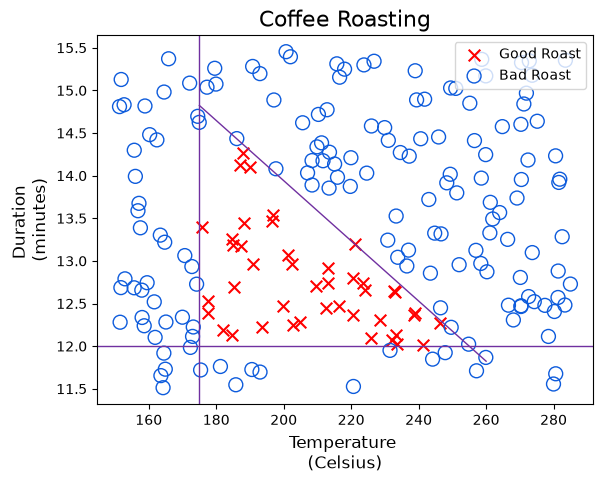

In [2]:
X, Y = load_coffee_data()
print(X.shape, Y.shape)

# 绘制咖啡烘培数据
plt_roast(X, Y)

## 数据归一化

对数据进行归一化后，拟合权重的过程(也就是反向传播)会更快
下面使用 Keras 归一化层对数据进行归一化
* 创建归一化层
* 对数据调用`adapt`，学习数据集的均值和方差，并在内部保存这些值
* 对数据进行归一化

In [3]:
print(f"Temperature Max, Min pre normalization: {np.max(X[:,0]):0.2f}, {np.min(X[:,0]):0.2f}")
print(f"Duration    Max, Min pre normalization: {np.max(X[:,1]):0.2f}, {np.min(X[:,1]):0.2f}")
norm_l = tf.keras.layers.Normalization(axis=-1)
norm_l.adapt(X)  # 学习均值和方差
Xn = norm_l(X)
print(f"Temperature Max, Min post normalization: {np.max(Xn[:,0]):0.2f}, {np.min(Xn[:,0]):0.2f}")
print(f"Duration    Max, Min post normalization: {np.max(Xn[:,1]):0.2f}, {np.min(Xn[:,1]):0.2f}")

Temperature Max, Min pre normalization: 284.99, 151.32
Duration    Max, Min pre normalization: 15.45, 11.51
Temperature Max, Min post normalization: 1.66, -1.69
Duration    Max, Min post normalization: 1.79, -1.70


In [4]:
# 复制数据，增大训练集并减少训练轮次
Xt = np.tile(Xn, (1000, 1))
Yt = np.tile(Y, (1000, 1))

print(Xt.shape, Yt.shape)

(200000, 2) (200000, 1)


## 模型构建

我们只需要创建两个简单的全连接层，一个隐藏层，一个输出层，隐藏层有三个神经元，输出层有一个神经元

In [5]:
tf.random.set_seed(1234) # 设置随机种子，保证结果可复现
model = Sequential(
    [
        tf.keras.Input(shape=(2,)), # 输入层，两个特征，所以是一个二维数组
        Dense(3, activation="sigmoid", name = 'layer1'), # 隐藏层，3个神经元，激活函数为 sigmoid
        Dense(1, activation="sigmoid", name = 'layer2'), # 输出层，1个神经元，激活函数为线性
    ]
)

model.summary() # 提供模型的描述


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ layer1 (Dense)                  │ (None, 3)              │             9 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer2 (Dense)                  │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13 (52.00 B)

 Trainable params: 13 (52.00 B)

 Non-trainable params: 0 (0.00 B)

In [6]:
# 查看实例化的权重和偏置
W1, b1 = model.get_layer("layer1").get_weights()
W2, b2 = model.get_layer("layer2").get_weights()
print(f"W1{W1.shape}:\n", W1, f"\nb1{b1.shape}:", b1)
print(f"W2{W2.shape}:\n", W2, f"\nb2{b2.shape}:", b2)

W1(2, 3):
 [[-0.24  0.98 -1.07]
 [ 0.22  0.06 -0.65]] 
b1(3,): [0. 0. 0.]
W2(3, 1):
 [[-1.22]
 [ 0.78]
 [ 1.16]] 
b2(1,): [0.]


In [7]:
model.compile(
    loss = tf.keras.losses.BinaryCrossentropy(),
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.01),
) # 定义损失函数并指定用于编译模型的优化器

model.fit(Xt, Yt, epochs=10) # 训练模型，执行梯度下降，将权重拟合到数据

Epoch 1/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 6s 880us/step - loss: 0.1884
Epoch 2/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 6s 963us/step - loss: 0.1190
Epoch 3/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 6s 988us/step - loss: 0.0707
Epoch 4/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 6s 995us/step - loss: 0.0190
Epoch 5/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 5s 873us/step - loss: 0.0113
Epoch 6/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 5s 856us/step - loss: 0.0076
Epoch 7/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 6s 930us/step - loss: 0.0052
Epoch 8/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 6s 908us/step - loss: 0.0036
Epoch 9/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 6s 876us/step - loss: 0.0025
Epoch 10/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 6s 952us/step - loss: 0.0018


In [8]:
# 查看更新后的权重
W1, b1 = model.get_layer("layer1").get_weights()
W2, b2 = model.get_layer("layer2").get_weights()
print(f"W1{W1.shape}:\n", W1, f"\nb1{b1.shape}:", b1)
print(f"W2{W2.shape}:\n", W2, f"\nb2{b2.shape}:", b2)

W1(2, 3):
 [[ 14.44 -11.01   0.15]
 [ 12.07  -0.25  10.34]] 
b1(3,): [  1.96 -11.88  12.44]
W2(3, 1):
 [[-45.99]
 [-53.02]
 [ 43.47]] 
b2(1,): [-13.6]


## 预测

训练好模型之后，我们可以使用模型来预测，模型输出是一个概率，要做出决策，需要设置阈值，这里使用阈值 0.5

先创建输入模型，模型接收一个或多个样本，矩阵的每一行代表一个样本。本例有两个特征，因此矩阵形状为 (m, 2)，其中 m 是样本数量

我们对输入特征进行了归一化，那么测试数据也必须归一化

In [9]:
X_test = np.array([
    [200, 13.9], # 正样本
    [200, 17], # 负样本
])
X_testn = norm_l(X_test)
predictions = model.predict(X_testn)
print("predict: \n", predictions)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
predict: 
 [[9.84e-01]
 [9.62e-08]]


In [10]:
# 将概率转换为决策
yhat = np.zeros_like(predictions)
for i in range(len(predictions)):
    if predictions[i] >= 0.5:
        yhat[i] = 1
    else:
        yhat[i] = 0
print("decisions: \n", yhat)

decisions: 
 [[1.]
 [0.]]


## 各层的函数

我们来查看一下各单元的函数，以确定它们在咖啡烘培决策中的作用，我们将针对所有输入值(时长，温度)绘制各节点的输出，各个单元都是逻辑函数，输出范围为 0 到 1，颜色深浅表示输出值

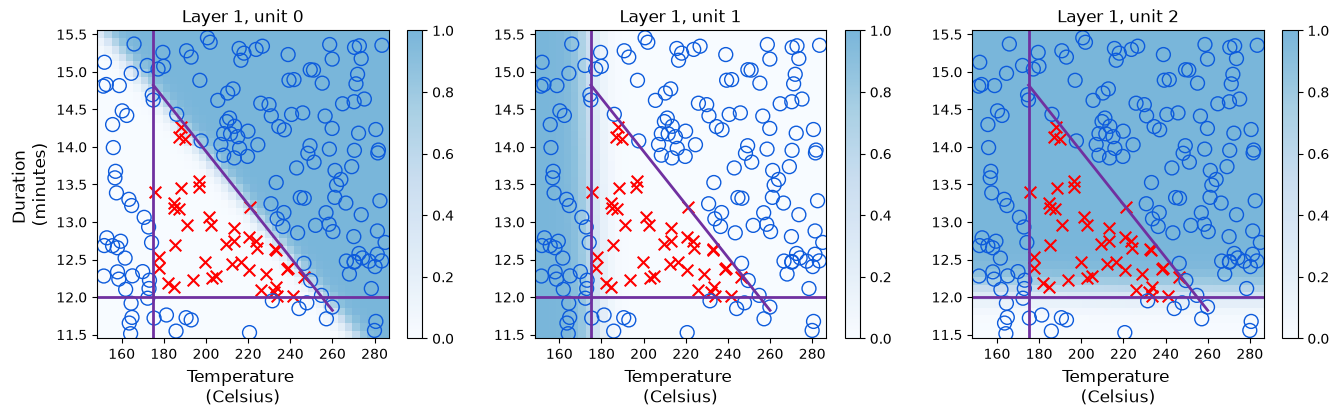

In [11]:
import importlib
import lab_coffee_utils

importlib.reload(lab_coffee_utils)
from lab_coffee_utils import plt_layer, plt_network, plt_output_unit

# 查看隐藏层的三个神经元
plt_layer(X, Y.reshape(-1, ), W1, b1, norm_l)

颜色深浅表明，每个单元负责不同的烘焙不佳区域，神经网络通过梯度下降过程自行学会了这些，但是现在看来效果并不好，后面给出一套提前训练好的参数，那个效果好

然后是最后一层的可视化，第一层使用 sigmoid，因此输出范围为 0 到 1，可以创建三维图，计算三个输入所有可能组合对应的输出

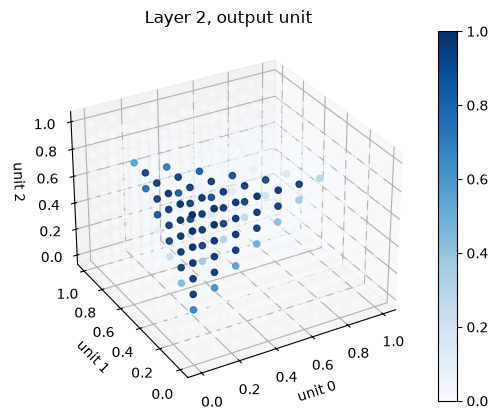

In [12]:
#  查看最后一层的可视化
plt_output_unit(W2, b2)

然后是最后一组图，表示神经网络的运行效果

左图通过蓝色深浅表示最后一层的原始输出，并叠加了以 X 和 O 表示的训练数据。右图应用决策阈值

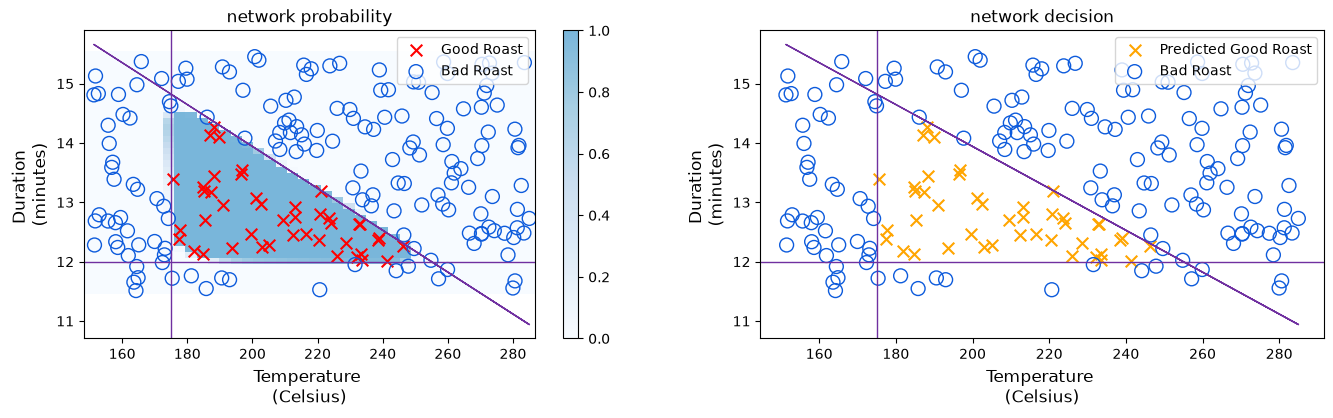

In [13]:
plt_network(
    X, Y,
    lambda x: model(norm_l(x), training=False).numpy()
)

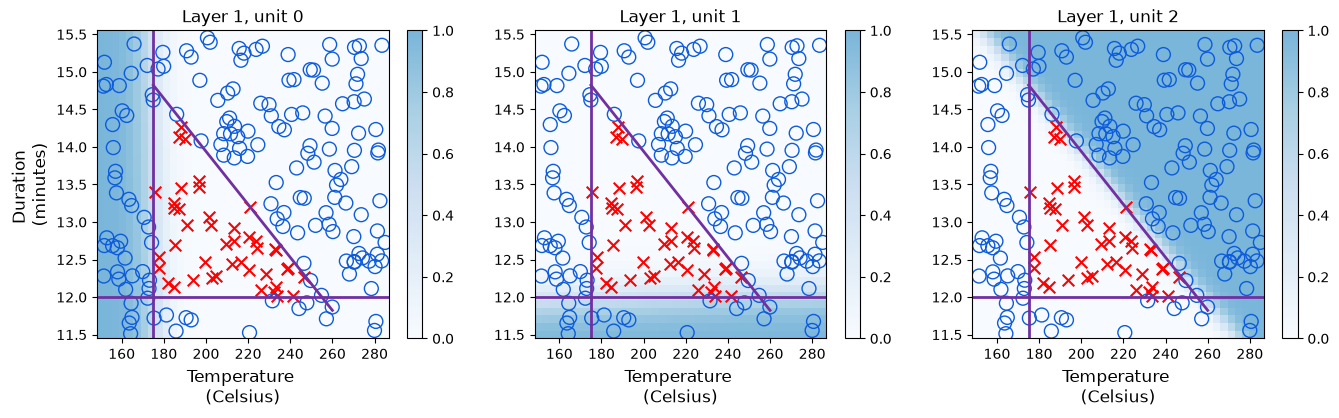

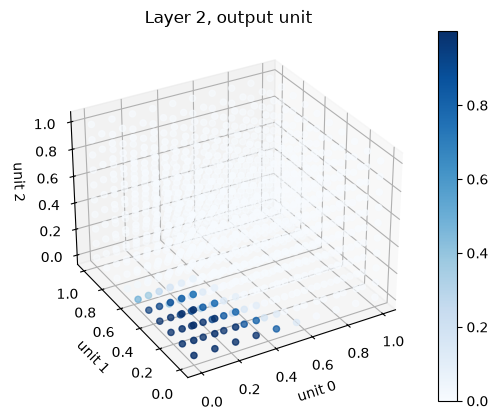

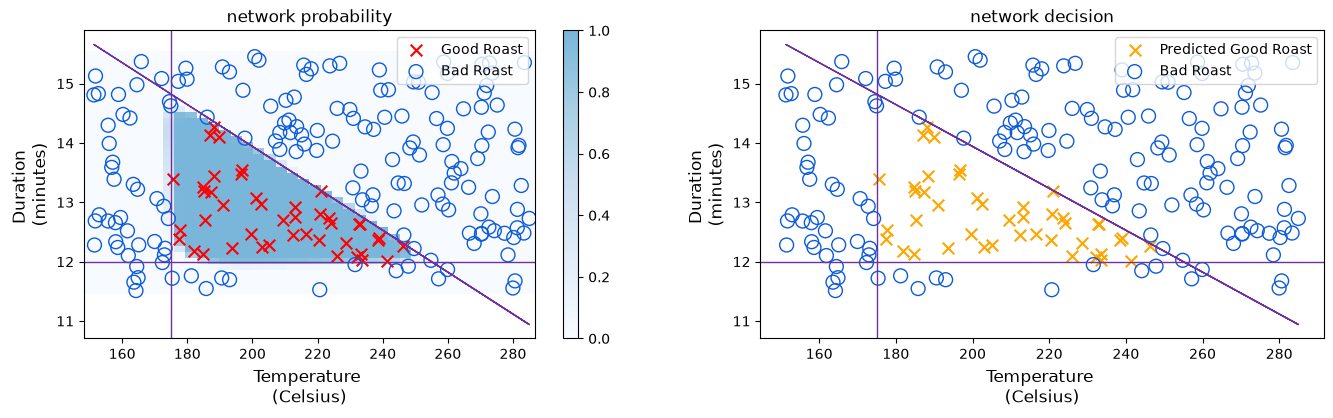

In [14]:
# 现在使用 参考实验 给的一次权重
W1 = np.array([
    [-8.94,  0.29, 12.89],
    [-0.17, -7.34, 10.79]] )
b1 = np.array([-9.87, -9.28,  1.01])
W2 = np.array([
    [-31.38],
    [-27.86],
    [-32.79]])
b2 = np.array([15.54])
model.get_layer("layer1").set_weights([W1,b1])
model.get_layer("layer2").set_weights([W2,b2])

plt_layer(X, Y.reshape(-1, ), W1, b1, norm_l)
plt_output_unit(W2, b2)
plt_network(
    X, Y,
    lambda x: model(norm_l(x), training=False).numpy()
)


这个第一层就很好了，每个单元负责不同的烘焙不佳区域，温度较低时，单元 0 的输出值较大，时长较短时，单元 1 的输出值较大，时长与温度组合不合适时，单元 2 的输出值较大

这些函数与人为了相同决策而可能选择的函数十分相似

然后第二张图，最大输出出现在三个输入都较小的区域，对应 烘焙良好 区域